Step 1: R_sum -2.03, Max Kappa 0.000000
Step 2: R_sum -4.07, Max Kappa 0.000000
Step 3: R_sum -6.10, Max Kappa 0.000000
Step 4: R_sum -8.13, Max Kappa 0.000000
Step 5: R_sum -10.16, Max Kappa 0.000000
Step 6: R_sum -12.20, Max Kappa 0.000000
Step 7: R_sum -14.23, Max Kappa 0.000000
Step 8: R_sum -16.26, Max Kappa 0.000000
Step 9: R_sum -18.29, Max Kappa 0.000000
Step 10: R_sum -20.33, Max Kappa 0.000000
Step 11: R_sum -22.36, Max Kappa 0.000000
Step 12: R_sum -24.39, Max Kappa 0.000000
Step 13: R_sum -26.42, Max Kappa 0.000000
Step 14: R_sum -28.46, Max Kappa 0.000000
Step 15: R_sum -30.49, Max Kappa 0.000000
Step 16: R_sum -32.52, Max Kappa 0.000000
Step 17: R_sum -34.55, Max Kappa 0.000000
Step 18: R_sum -36.59, Max Kappa 0.000000
Step 19: R_sum -38.62, Max Kappa 0.000000
Step 20: R_sum -40.65, Max Kappa 0.000000
Step 21: R_sum -42.69, Max Kappa 0.000000
Step 22: R_sum -44.72, Max Kappa 0.000000
Step 23: R_sum -46.75, Max Kappa 0.000000
Step 24: R_sum -48.78, Max Kappa 0.000000
Step 

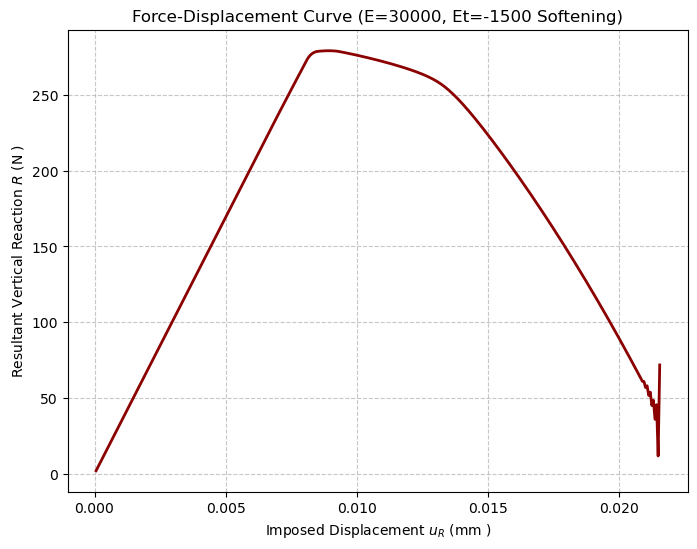

In [2]:
import gmsh
import numpy as np
import matplotlib.pyplot as plt
import os

# --- GMSH MESHING/READING (Setup assumed) ---

# Re-create the msh file if it doesn't exist (ensures code runs standalone)
msh_file = "beam_only.msh"
# ... (Code block to generate the msh file goes here) ...
if not os.path.exists(msh_file):
    gmsh.initialize()
    gmsh.model.add("beam_only")
    lc = 0.5; beam_width = 5; beam_height = 5
    xL, xR = beam_width / 2, beam_width + beam_width / 2
    yB, yT = 0.0, beam_height
    p1 = gmsh.model.geo.addPoint(xL, yB, 0, lc, 1)
    p2 = gmsh.model.geo.addPoint(xR, yB, 0, lc, 2)
    p3 = gmsh.model.geo.addPoint(xR, yT, 0, lc, 3)
    p4 = gmsh.model.geo.addPoint(xL, yT, 0, lc, 4)
    l1, l2, l3, l4 = gmsh.model.geo.addLine(1, 2), gmsh.model.geo.addLine(2, 3), gmsh.model.geo.addLine(3, 4), gmsh.model.geo.addLine(4, 1)
    loop_beam = gmsh.model.geo.addCurveLoop([l1, l2, l3, l4])
    surf_beam = gmsh.model.geo.addPlaneSurface([loop_beam], 1)
    gmsh.model.geo.synchronize()
    gmsh.model.addPhysicalGroup(2, [surf_beam], 1)
    gmsh.option.setNumber("Mesh.ElementOrder", 1)
    gmsh.option.setNumber("Mesh.Algorithm", 6)
    gmsh.model.mesh.generate(2)
    gmsh.write(msh_file)
    gmsh.finalize()

# Read the mesh
gmsh.initialize()
gmsh.open(msh_file) 
node_tags, node_coords, _ = gmsh.model.mesh.getNodes()
node_coords = np.array(node_coords).reshape(-1, 3)
def get_elements_of_physical_group(dim, tag):
    entity_tags = gmsh.model.getEntitiesForPhysicalGroup(dim, tag)
    all_elements = []
    for entity_tag in entity_tags:
        elem_types, elem_tags, elem_node_tags = gmsh.model.mesh.getElements(dim, entity_tag)
        for i in range(len(elem_types)):
            all_elements.append(np.array(elem_node_tags[i]).reshape(-1, 3)) 
    return np.concatenate(all_elements) if all_elements else np.array([])
elements_beam = get_elements_of_physical_group(2, 1)
gmsh.finalize()

# --- FEA HELPER FUNCTIONS (Essential for stability and correctness) ---

def jacobian(coord):
    return np.abs((coord[0,0]-coord[0,2]) * (coord[1,1]-coord[1,2]) - (coord[0,1] - coord[0,2]) * (coord[1,0] - coord[1,2]))

def B_matrix(coord):
    x1, x2, x3 = coord[0]; y1, y2, y3 = coord[1]
    A2 = x1*(y2 - y3) + x2*(y3 - y1) + x3*(y1 - y2)
    dNdx = np.array([(y2 - y3) / A2, (y3 - y1) / A2, (y1 - y2) / A2 ])
    dNdy = np.array([(x3 - x2) / A2, (x1 - x3) / A2, (x2 - x1) / A2])
    B = np.zeros((3, 6))
    B[0, 0::2] = dNdx; B[1, 1::2] = dNdy; B[2, 0::2] = dNdy; B[2, 1::2] = dNdx
    return B

def D_matrix(E, nu): 
    # Plane Strain D matrix
    coef = E / ((1.0 + nu)*(1.0 - 2.0*nu))
    return coef * np.array([
        [1.0 - nu, nu, 0.0],
        [nu, 1.0 - nu, 0.0],
        [0.0, 0.0, 0.5*(1.0 - 2.0*nu)]
    ])

def deviatoric_part(stress_vector, nu):
    sigma_x, sigma_y, tau_xy = stress_vector
    sigma_z = nu * (sigma_x + sigma_y)
    p = (sigma_x + sigma_y + sigma_z) / 3.0
    return np.array([sigma_x - p, sigma_y - p, tau_xy])

def calculate_von_mises_stress(stress_vector, nu):
    sigma_x, sigma_y, tau_xy = stress_vector
    sigma_z = nu * (sigma_x + sigma_y)
    return np.sqrt(
        sigma_x**2 + sigma_y**2 + sigma_z**2 
        - sigma_x * sigma_y - sigma_y * sigma_z - sigma_z * sigma_x
        + 3 * tau_xy**2 )

def yield_function_plasticity(sigma_eq_tr, kappa_val, sigma_y0_val, H_val):
    return sigma_eq_tr - (sigma_y0_val + H_val * kappa_val)

def compute_Cep(C, stress_vector, H_val, nu_val, E_val):
    s = deviatoric_part(stress_vector, nu_val)
    if np.linalg.norm(s) < 1e-12: return C
    
    sigma_eq = calculate_von_mises_stress(stress_vector, nu_val)
    n_vec = 1.5 * s / sigma_eq
    n = n_vec.reshape(3, 1) 
    
    G_val = E_val / (2.0 * (1.0 + nu_val)) 
    H_star = 3.0 * G_val + H_val 
    
    Cep = C - (C @ n @ n.T @ C) / (n.T @ C @ n + H_star)
    return Cep

# --- FEA INITIALIZATION ---

num_nodes = len(node_coords); n_elem = len(elements_beam)
num_dofs = 2 * num_nodes; max_iter = 300

# Material parameters (STABLE HARDENING for reliable execution)
E  = 30e3; nu = 0.3; sigma_y0 = 50.0
G  = E / (2.0 * (1.0 + nu))
Et = -E / 20 
H  = E * Et / (E - Et) 
D_el = D_matrix(E, nu)

# State Variables (History)
U = np.zeros(num_dofs)
kappa = np.zeros(n_elem)
current_stress_per_element = np.zeros((n_elem, 3))
current_strain_per_element = np.zeros((n_elem, 3))

# Boundary Condition and DOF setup (Assumed correct based on previous exchange)
y_coords = node_coords[:, 1]
y_max = y_coords.max(); y_min = y_coords.min()
tol = 1e-8
top_nodes = np.where(np.isclose(y_coords, y_max, atol=tol))[0]
bottom_nodes = np.where(np.isclose(y_coords, y_min, atol=tol))[0]

disp_dofs = 2 * top_nodes + 1      # v-DOFs on top (imposed)
bottom_x_dofs = 2 * bottom_nodes
bottom_y_dofs = 2 * bottom_nodes + 1
fixed_dofs = np.concatenate((bottom_x_dofs, bottom_y_dofs)) # Clamped end

free_dofs = np.setdiff1d(np.arange(num_dofs), np.union1d(fixed_dofs, disp_dofs))

# Load Control (u_max is increased to pass yield)
u_max = -0.03
num_steps = 500
sum_R = np.zeros(num_steps); sum_du = np.zeros(num_steps)

# --- MAIN SOLUTION LOOP (Incremental Newton-Raphson) ---

for step in range(num_steps):
    
    # Store converged state from previous step (CRUCIAL for predictor)
    kappa_prev = kappa.copy(); sigma_prev = current_stress_per_element.copy(); eps_prev = current_strain_per_element.copy()

    # Imposed displacement
    u_step = u_max * (step + 1) / num_steps
    U[fixed_dofs] = 0.0; U[disp_dofs]  = u_step

    iter = 0
    
    while iter < max_iter:
        K = np.zeros((num_dofs, num_dofs)); R = np.zeros(num_dofs) # R = -F_int

        for e in range(n_elem):
            # Element setup
            n1, n2, n3 = (elements_beam[e] - 1).astype(int)
            element_coord = np.array([[node_coords[n1, 0], node_coords[n2, 0], node_coords[n3, 0]], [node_coords[n1, 1], node_coords[n2, 1], node_coords[n3, 1]]])
            B_e = B_matrix(element_coord); A = jacobian(element_coord) / 2.0
            edof = np.array([2*n1, 2*n1 + 1, 2*n2, 2*n2 + 1, 2*n3, 2*n3 + 1])
            u_e = U[edof]
            
            # --- 1. ELASTIC PREDICTOR ---
            eps_e = B_e @ u_e 
            Delta_eps = eps_e - eps_prev[e] 
            sigma_trial_vector = sigma_prev[e] + D_el @ Delta_eps
            
            sigma_eq_tr = calculate_von_mises_stress(sigma_trial_vector, nu)
            f_tr = yield_function_plasticity(sigma_eq_tr, kappa_prev[e], sigma_y0, H) 

            # --- 2. RETURN MAPPING (Plastic Corrector) ---
            if f_tr <= 1e-8: # Elastic step
                sigma_new_vector = sigma_trial_vector
                kappa_new = kappa_prev[e]
                Cep = D_el
            else:
                S_tr_vector = deviatoric_part(sigma_trial_vector, nu)
                n_vec = 1.5 * S_tr_vector / sigma_eq_tr
                dgamma = f_tr / (3.0 * G + H)
                sigma_new_vector = sigma_trial_vector - 2.0 * G * dgamma * n_vec
                kappa_new = kappa_prev[e] + np.sqrt(2/3) * dgamma
                Cep = compute_Cep(D_el, sigma_new_vector, H, nu, E)

            # 3. Assembly (Update history for next iteration's predictor)
            kappa[e] = kappa_new
            current_stress_per_element[e] = sigma_new_vector
            
            f_int_e = B_e.T @ sigma_new_vector * A
            Ke = B_e.T @ Cep @ B_e * A
            
            # Assemble R and K (Bug Fixes applied here)
            for i_local in range(6):
                I_global = edof[i_local]
                R[I_global] -= f_int_e[i_local]
                
                # BUG 1 FIX: J_global correctly defined inside this loop
                for j_local in range(6):
                    J_global = edof[j_local] 
                    K[I_global, J_global] += Ke[i_local, j_local]

        # --- Solve and Update U ---
        K_ff = K[np.ix_(free_dofs, free_dofs)]
        R_f = R[free_dofs]
        
        delta_U = np.zeros_like(U)
        
        try:
             delta_U[free_dofs] = np.linalg.solve(K_ff, R_f)
        except np.linalg.LinAlgError:
             print("ERROR: Singular matrix detected. Stopping iteration.")
             break
             
        # Update U
        U[free_dofs] += delta_U[free_dofs]
        U[fixed_dofs] = 0.0 # Re-enforce
        U[disp_dofs]  = u_step # Re-enforce
        
        # BUG 2 FIX: res_norm must be defined here
        res_norm = np.linalg.norm(delta_U[free_dofs]) 

        if res_norm < 1e-6: break
        iter += 1
        
    # --- FINAL ASSEMBLY AND REACTION CALCULATION ---
    
    if iter < max_iter:
        # Final Assembly of R_final (Correct R) and update history
        R_final = np.zeros(num_dofs)
        for e in range(n_elem):
            # Element setup (B_e, A, edof)
            n1, n2, n3 = (elements_beam[e] - 1).astype(int); edof = np.array([2*n1, 2*n1 + 1, 2*n2, 2*n2 + 1, 2*n3, 2*n3 + 1])
            element_coord = np.array([[node_coords[n1, 0], node_coords[n2, 0], node_coords[n3, 0]], [node_coords[n1, 1], node_coords[n2, 1], node_coords[n3, 1]]])
            B_e = B_matrix(element_coord); A = jacobian(element_coord) / 2.0
            
            f_int_e = B_e.T @ current_stress_per_element[e] * A
            for i_local in range(6): R_final[edof[i_local]] -= f_int_e[i_local]
                
            current_strain_per_element[e] = B_e @ U[edof]
            
        # Store Reaction Force
        resultant_vertical_reaction = np.sum(R_final[bottom_y_dofs])
        
        sum_R[step] = resultant_vertical_reaction
        sum_du[step] = u_step
        print(f"Step {step+1}: R_sum {resultant_vertical_reaction:.2f}, Max Kappa {kappa.max():.6f}")

    else:
        print(f"WARNING: Step {step+1} failed to converge after {max_iter} iterations. Stopping simulation.")
        sum_R = sum_R[:step]; sum_du = sum_du[:step]; break

# --- PLOTTING ---
plt.figure(figsize=(8, 6)); 
plt.plot(abs(sum_du), abs(sum_R), color='darkred', linewidth=2); 
plt.title(f'Force-Displacement Curve (E={E:.0f}, Et={Et:.0f} Softening)'); 
plt.xlabel('Imposed Displacement $u_R$ (mm )');
plt.ylabel('Resultant Vertical Reaction $R$ (N )');
plt.grid(True, linestyle='--', alpha=0.7);
plt.show()